# Miary jakości modelu

W tym ćwiczeniu skorzystamy z modułu sklearn [scikit-learn](https://scikit-learn.org/stable/auto_examples/index.html) (importujemy go jako `sklearn`) przeznaczonego do uczenia maszynowego, w szczególności do modeli klasycznych. Zawiera wiele zoptymalizowanych i przydatnych funkcji i algorytmów. Alternatywnymi frameworkami, nastawionymi głównie na sieci neuronowe, są np. [PyTorch](https://pytorch.org/tutorials/), [Tensorflow](https://www.tensorflow.org/tutorials), [Keras](https://keras.io/examples/), [Caffe2](https://caffe2.ai/docs/tutorials), chociaż z obserwacji środowiska wynika, że dominują raczej PyTorch i Tensorflow.

### Przygotowanie środowiska programistycznego

In [215]:
import sklearn
print('Zainstalowana wersja scikit-learn: {}.'.format(sklearn.__version__))

import numpy as np

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

import pandas as pd

Zainstalowana wersja scikit-learn: 1.6.1.


### Przygotowanie syntetycznych danych

Nasze przykłady będą należały do dwu klas: **0** lub **1**. Wartości zmiennych wejściowych $(x, y)$ dla danej klasy są dane dwuwymiarowym rozkładem Gaussa:

$$
p_{class~1}(x,y) = N(\mu_{class~1, x}, \mu_{class~1, y}, \text{covariance})
$$

W bibliotece numpy wielowymiarowe rozkłady Gaussa można uzyskać za pomocą funkcji `np.random.default_rng().multivariate_normal()`

**Proszę:**

* uzupełnić kod funkcji ```generate_class_points(nPoints, means, covariance, class)``` która zwraca macierz $(nPoints, 3)$ zawierającą położenia punktów danej klasy, oraz jej numer: (x,y,class) funkcja na wejściu przyjmuje:
    * liczbę przykładów do generacji $nPoints$, macierze $means$ i $covariance$ zawierające średnie i kowariancję dla danej klasy:
$$
means = [\mu_{x}, \mu_{y}]
$$
$$
covariance =
\begin{bmatrix}
    \sigma^{2}_{x} & \sigma_{xy} \\
    \sigma_{xy} & \sigma^{2}_{y}
\end{bmatrix}   
$$
    * liczbę kodującą numer klasy : $class$, w naszym przypadku 0 lub 1


**Proszę:**

używając z funkcji  ```generate_class_points(nPoints, means, covariance)``` wygenenerować po 5000 punktów dla dwu klas, dla których parametry rozkładów Gaussa są następujące:

```Python
means_class_0 = np.array([1,5])
covariance_class_0 = np.diag([3,3])

means_class_1 = np.array([4,7])
covariance_class_1 = np.diag([3,2])
```

Dane proszę załadować do obiektów pandas DataFrame dla każdej z klas, a następnie je połączyć korzystając z funkcji ```pandas.concatenate()```.

In [216]:
def generate_class_data(nPoints, means, covariances, label):
    #Generacja własności - w naszym wypadku wartości (x,y) dla danej klasy
    features=np.random.default_rng().multivariate_normal(means,covariances,size=nPoints)
    #Generacja macierzy z etykietami - tutaj numerem klasy
    labels = np.full((nPoints,1), label)
    #Połączenie macierzy dla własności i etykiet w jedną macierz
    class_data = np.concatenate((features, labels), axis=1)
    return class_data

nPoints = 5000

#Defincja parametrów rozkładu Gaussa dla klasy "0"
means_class_0 = np.array([1,5])
covariance_class_0 = np.diag([3,3])

means_class_1 = np.array([4,7])
covariance_class_1 = np.diag([3,2])
#Generacja danych dla klas "0" i "1"
class_0_data=generate_class_data(nPoints,means_class_0,covariance_class_0,0)
class_1_data=generate_class_data(nPoints,means_class_1,covariance_class_1,1)

#Sprawdzenie czy wygenerowane dane mają poprawny kształt
print("class_0_data.shape ",class_0_data.shape)
print("class_1_data.shape ",class_1_data.shape)

#Utworzenie obiektu DataFrame dla klas "0" i "1"
df_class_0=pd.DataFrame(class_0_data)
df_class_1=pd.DataFrame(class_1_data)

#Utworzenie obiektu DataFrame dla obu klas łącznie
df = pd.concat([df_class_0, df_class_1], ignore_index=True)
#Wymieszanie obiektu DataFrame dla obu klas łącznie
df = df.sample(frac=1, ignore_index=True)
df.rename(columns={0:"x",1:"y",2:"klasa"},inplace=True)
#Wypisanie zawartości obiektu DataFrame dla obu klas łącznie
print(df)

class_0_data.shape  (5000, 3)
class_1_data.shape  (5000, 3)
             x         y  klasa
0    -0.989385  5.865448    0.0
1    -0.158753  4.031422    0.0
2     3.597312  5.466441    1.0
3     3.332889  8.243136    1.0
4     3.882404  3.335844    0.0
...        ...       ...    ...
9995  3.825183  6.587346    1.0
9996  0.603858  6.025588    0.0
9997  2.798377  5.482531    0.0
9998  1.084523  4.320947    0.0
9999  4.573174  7.775492    1.0

[10000 rows x 3 columns]


## Analiza wizualna danych.

Pierwszy krok przy analizie danych z użyciem dowolnego algorytmu to ich inspekcja. Korzystając z funkcji biblioteki `plotly.express`:
* narysować rozkłady wszystkich zmiennych wejściowych oddzielnie dla klas 0 i 1 (`px.histogram()` - Zwróć uwagę na parametr barmode, zobacz co się stanie dla "group" a co jak go zmienisz na "overlay".)
* narysować wykres korelacji między zmiennymi wejściowymi dla klas 0 i 1 na jednym rysunku (`px.scatter()`)

In [217]:
fig=go.Figure()

fig.add_trace(go.Histogram(x=df_class_0[0]))
fig.add_trace(go.Histogram(x=df_class_0[1]))

fig.update_layout(barmode='overlay')
fig.update_traces(opacity=0.75)
fig.show()

figa=go.Figure()
figa.add_trace(go.Histogram(x=df_class_1[0]))
figa.add_trace(go.Histogram(x=df_class_1[1]))

figa.update_layout(barmode='overlay')
figa.update_traces(opacity=0.75)
figa.show()

figb=px.scatter(df,x="x",y="y",color="klasa")
figb.show()

# Przypadek klas równolicznych

* podziel pełne dane na podzbiory treningowy (80% danych) i testowy (20% danych). Wykonując podział zwróć uwagę na randomizację i stratyfikację danych.
* narysuj dwuwymiarowe rozkłady dla zbiorów treningowego i testowego i sprawdź wizualnie czy są różne.

**Wskazówka:** do podziałów zbioru proszę użyć funkcji [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) podając obiekt DataFrame jako argument.

In [218]:
df_train,df_test=sklearn.model_selection.train_test_split(df)

fig1=go.Figure()

fig1.add_trace(go.Histogram(x=df_train["x"]))
fig1.add_trace(go.Histogram(x=df_train["y"]))

fig1.update_layout(barmode='overlay')
fig1.update_traces(opacity=0.75)
fig1.show()

## Trening regresji logistycznej

Skorzystamy z implementacji regresji logistycznej z pakietu scikit-learn.
Regresja logistyczna zaimplementowana jest w klasie [`LogisticRegression`](http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

**Proszę:**

* stworzyć obiekt klasy ```LogisticRegression()```
* użyć tego obiektu by wytrenować model. W tym miejscu wykonają się kroki odpowiadające procedurze minimalizacji znajdującej parametry $\theta$ z zajęć o regresji logistycznej
* przeprowadzić predykcję na zbiorze testowym

**Wskazówka:** domyślną funkcją minimalizacji jest 'lbfgs', ale warto ją podać explicite by uniknąć uciążliwego ostrzeżenia.

In [219]:
#Definicja modelu - obiektu klasy LogisticRegression
model=LogisticRegression(solver='lbfgs')
#Przeprowadzenie minmalizacji, inaczej dopasowania, parametrów modelu (ang. fit) trenowania modelu
model.fit(X=df_train[["x","y"]],y=df_train["klasa"])

#Przeprowadzenie predykcji. Czym różnią się te dwie opcje?
y_pred = model.predict(df_test[["x","y"]])
y_prob = model.predict_proba(df_test[["x","y"]])
print("y_pred:", y_pred)
print("y_prob:\n", y_prob)

y_pred: [0. 1. 0. ... 0. 1. 1.]
y_prob:
 [[0.66660852 0.33339148]
 [0.01838255 0.98161745]
 [0.63651309 0.36348691]
 ...
 [0.98977273 0.01022727]
 [0.19533905 0.80466095]
 [0.06985983 0.93014017]]


**Proszę**

* obliczyć i narysować macierz pomyłek (ang. confusion matrix)

**Wsakzówki:**
* skorzystaj z funkcji ```metrics.confusion_matrix()``` by wypisać wartości macierzy
* skorzystaj z funkcji ```ConfusionMatrixDisplay.from_estimator()``` by narysować macierz pomyłek podając model jako argument funkcji.
  * Narysuj macierz zwykłą oraz znormalizowaną (znajdź odpowiedni argument w dokumentacji).
  * Zwróć uwagę na różne wersje normalizacji. Porównaj z [tabelą ](https://en.wikipedia.org/wiki/Receiver_operating_characteristic#Basic_concept).

**Pytanie**: jaką iterpretację mają elementy macierzy po normalizacji?

[[1081  207]
 [ 197 1015]]


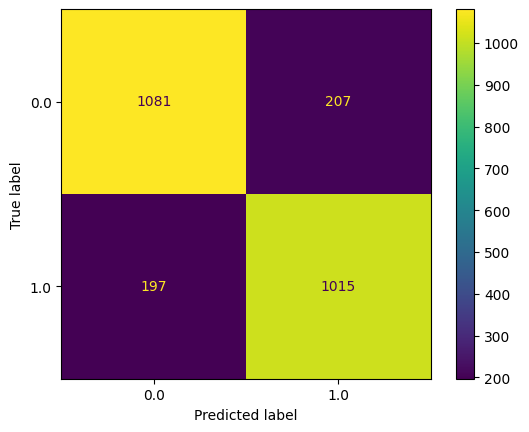

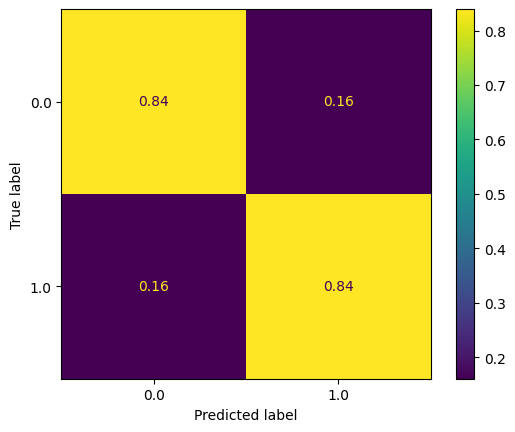

In [220]:
#Obliczenie macierzy pomyłek
cm = confusion_matrix(df_test["klasa"], y_pred)
#Wypisanie macierzy pomyłek w postaci tekstowej
print(cm)

#Narysowanie macierzy pomyłek.

ConfusionMatrixDisplay.from_estimator(model,df_test[["x","y"]],df_test["klasa"])

#Narysowanie macierzy pomyłek z normalizacją względem liczby przykładów w prawdziwych przykładów.
ConfusionMatrixDisplay.from_estimator(model,df_test[["x","y"]],df_test["klasa"],normalize="true")

Zdefiniujmy następujące przypadki gdy nasz model się myli lub podaje poprawny wynik:

* **"True Positive" (TP)**:  stan faktyczny jest pozytywny (y=1) i klasyfikator się nie myli (wynik = 1)
* **"True Negative" (TN)**:  stan faktyczny jest negatywny (y=0) i klasyfikator się nie myli (wynik = 0)
* **"False Positive" (FP)**: wynik fałszywie pozytywny (fałszywy alarm): stan faktyczny jest negatywny (y=0) ale klasyfikator się  myli (wynik = 1)
* **"False Netative" (FN)**: przegapiony alarm: stan faktyczny jest pozytywny (y=1) i klasyfikator się myli (wynik = 0)

Zbadajmy wartości różnych miar jakości:

* **precyzja pozytywna - _precision_ (positive predictive value (PPV)):**

$\qquad$ $PPV = \frac{TP}{P'}=\frac{TP}{ TP + FP}$

Ułamek przypadków oznaczonych jako klasa "1" który naprawdę należy do klasy "1". Ułamek ten jest np. odpowiedzą na pytanie
"Jeśli wynik testu jest pozytywny, jakie jest prawdopodobieństwo, że osoba badana jest chora?"

* **czułość - _recall_ (ang. True Positive Rate, TPR):**

$\qquad$ $TPR = \frac{TP}{ P} = \frac{TP} { TP+FN}$

Ułamek przypadków które należą do klasy "1" i został poprawnie oznaczony. Ułamek ten jest np. odpowiedzą na pytanie  "Jakie jest prawdopodobieństwo, że test wykonany dla osoby chorej wykaże, że jest ona chora?"


* **dokładność - _accuracy_ (ACC)):** Prawdopodobieństwo prawidłowej klasyfikacji.

$\qquad$ $ACC = \frac{TP + TN}{P + N}$

Ułamek przypadków, niezależnie od klasy, które zostały poprawnie oznaczone. Ułamek ten jest np. odpowiedzą na pytanie  "Jakie jest prawdopodobieństwo, że test poda poprawną odpowiedź?"

* **F1-score:** średnia harmoniczna z precyzji i czułości:

$\qquad$ $F_1= 2 \frac{PPV  \cdot TPR}{PPV+TPR}= \frac{2TP}{ 2TP+FP+FN}$

Miara ta daje ocenę balansu między czułością a precyzją. Miara ta nie uwzględnia wyników prawdziwie negatywnych.

* **współczynnik korelacji Matthewsa ( Matthews correlation coefficient):**

$\qquad$ $
\text{MCC} = \frac{ TP \cdot TN - FP \cdot FN } {\sqrt{ (TP + FP) ( TP + FN ) ( TN + FP ) ( TN + FN ) } }
$

Współczynnik MMC uwzględnia wyniki zarówno prawdziwie jaki i fałszywie pozytywne i negatywne i jest na ogół uważany jako zrównoważona miara, która może być stosowana nawet wtedy, gdy klasy są bardzo różnej liczebności.

MCC jest w istocie współczynnikiem korelacji pomiędzy obserwowanymi i przewidywanymi klasyfikacjami binarnymi; zwraca wartość od -1 do +1.

* Współczynnik +1 odpowiada idealnej klasyfikacji,
* 0 nie lepiej niż losowe przypisanie wyniku
* -1 oznacza całkowitą niezgodę między klasyfikacją  i stanem faktycznym.

***

**Proszę**

uzupełnić funkcje:
*  ```train_model(X_test, X_train, y_train)```, która trenuje model ```LogisticRegression``` i zwraca **prawdopodobieństwa** wyestymowane dla X_test
* ```get_scores(y_true, y_prob, th=0.5)```, która zwraca słownik z miarami jakości modelu dla otrzymanych prawdopodobieństw. Parametr `th` to próg prawdopodobieństwa klasy 1 powyżej którego przypiszemy klasę 1 danemu przykładowi.

**Wskazówka** Opisane powyżej miary są dostępne w bibliotece [sklearn](https://scikit-learn.org/stable/api/sklearn.metrics.html#module-sklearn.metrics)

In [221]:
%%time
def train_model(X_test, X_train, y_train):
    # Inicjalizacja klasy modelu
    model=LogisticRegression(solver='lbfgs')
    # Dopasowanie modelu do danych treningowych
    model.fit(X=X_train,y=y_train)
    #Predykcja na zbiorze testowym
    y_prob = model.predict_proba(X_test)
    return y_prob

def get_scores(y_true, y_prob, th=0.5):
    #Przekształcenie prawdopodobieństw na etykiety klas
    lbls=np.where(y_prob>th,1,0)[:,1]
    #Obliczenie wartości miar jakości
    metrics_dict = {"PPV":sklearn.metrics.precision_score(y_true,lbls),
                    "TPR":sklearn.metrics.recall_score(y_true,lbls),
                    "ACC":sklearn.metrics.accuracy_score(y_true,lbls),
                    "F1":sklearn.metrics.f1_score(y_true,lbls),
                    "MCC":float(sklearn.metrics.matthews_corrcoef(y_true,lbls))}
    return metrics_dict


y_prob = train_model(df_test[["x","y"]], df_train[["x","y"]], df_train["klasa"])

metrics_dict = get_scores(df_test["klasa"], y_prob)
print(metrics_dict)


{'PPV': 0.8306055646481179, 'TPR': 0.8374587458745875, 'ACC': 0.8384, 'F1': 0.8340180772391126, 'MCC': 0.6766014448669514}
CPU times: user 55.3 ms, sys: 1.96 ms, total: 57.3 ms
Wall time: 49.2 ms


W czasie analizy wydajności modelu zwykle stosuje się modyfikację losowego podziału na dane treningowe i testowe. Całe dane są dzielone na
równych ```k``` podziałów (ang. folds) i jest przeprowadzana k-krotna procedura sprawdzania (ang. k-fold cross-validation, pl. walidacja krzyżowa):

0. dzielimy zbiór uczący (features, labels) na `k` równych części
1. odkładamy i-tą, i=(0,1,2,3,...,k-1), część jako dane testowe,
2. na pozostałych `k-1` częściach uczymy klasyfikator
3. obliczamy miary jakości na tej odłożonej części
4. wracamy do punktu 1
5. na końcu mozna policzyć wartości metryk uśrednione po podziałach

_**Co to jest stratyfikacja?**
Stratyfikacja to metoda podziału danych, która **zachowuje proporcje klas** w zbiorach treningowym i testowym takie same jak w oryginalnym zbiorze danych._

Procedura sprawdzania metryk z użyciem "k-fold cross-validation" jest zaimplementowana w pakiecie `sklearn` między innymi przez funkcję [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html#sklearn.model_selection.StratifiedKFold).


Funkcja ```cross_val_metrics(df, n_splits=5)``` wypisuje na ekran wartości metryk obliczone z użyciem walidacji krzyżowej. Funkcja przyjmuje na wejściu:
* df - obiekt DataFrame reprezentujący dane
* n_splits - liczba foldów na jaki mają być podzielone nasze dane

Funkcja korzysta ze stworzonych wcześniej funkcji: train_model oraz get_scores

**Proszę:**

* uzupełnić funkcję 'cross_val_metrics' by wypisywała wartości dla metryk precision, recall, accuracy, f1, matthews_corrcoef

In [239]:
def cross_val_metrics(df, n_splits=5, th=0.5):
    # Wydzielenie danych wejściowych i wyjściowych z df
    X = df[["x","y"]].values
    y = df["klasa"].values
    metrics_dict_cv = {'PPV': [], 'TPR': [], 'ACC': [], 'F1': [], 'MCC': []}
    # Inicjalizacja StratifiedKFold i pętla po podziałach
    skf=StratifiedKFold(n_splits=n_splits)
    skf.get_n_splits()
    for i, (train_index, test_index) in enumerate(skf.split(X, y)):
      y_prob=train_model(df.iloc[test_index][["x","y"]],df.iloc[train_index][["x","y"]],df.iloc[train_index]["klasa"])
      dict1=get_scores(df.iloc[test_index]["klasa"],y_prob,th)
      for key in dict1:
        metrics_dict_cv[key].append(dict1[key])
    # Wypisanie średnich i odchyleń standardowych dla każdej miary
    for key in metrics_dict_cv.keys():
        mean_val = np.mean(metrics_dict_cv[key])
        std_val = np.std(metrics_dict_cv[key])
        print(f"{key}: {mean_val:.3f} ± {std_val:.3f}")

cross_val_metrics(df)

PPV: 0.850 ± 0.009
TPR: 0.852 ± 0.002
ACC: 0.851 ± 0.006
F1: 0.851 ± 0.005
MCC: 0.701 ± 0.012


Wywołaj funkcję cross_val_metrics dla różnych wielkości zbioru danych treningowych: 5%, 10%, 50%, 70%, 90% całego zbioru danych. Porównaj wyniki.

In [227]:
for j in [0.05,0.1,0.5,0.7,0.9]:
  print(j)
  cross_val_metrics(df.sample(frac=j))


0.05
PPV: 0.826 ± 0.055
TPR: 0.824 ± 0.028
ACC: 0.828 ± 0.043
F1: 0.825 ± 0.041
MCC: 0.656 ± 0.086
0.1
PPV: 0.850 ± 0.027
TPR: 0.869 ± 0.015
ACC: 0.854 ± 0.019
F1: 0.859 ± 0.017
MCC: 0.708 ± 0.038
0.5
PPV: 0.848 ± 0.007
TPR: 0.845 ± 0.022
ACC: 0.848 ± 0.011
F1: 0.846 ± 0.013
MCC: 0.697 ± 0.023
0.7
PPV: 0.853 ± 0.008
TPR: 0.855 ± 0.019
ACC: 0.854 ± 0.008
F1: 0.854 ± 0.009
MCC: 0.707 ± 0.016
0.9
PPV: 0.852 ± 0.011
TPR: 0.854 ± 0.006
ACC: 0.853 ± 0.005
F1: 0.853 ± 0.004
MCC: 0.705 ± 0.010


Wywołaj funkcję cross_val_metrics dla różnych wartości parametru th ```[0.1, 0.5, 0.7]```. Porównaj wyniki.

In [228]:
for j in [0.1,0.5,0.7]:
  print(j)
  cross_val_metrics(df,th=j)


0.1
PPV: 0.668 ± 0.007
TPR: 0.985 ± 0.004
ACC: 0.748 ± 0.007
F1: 0.796 ± 0.004
MCC: 0.563 ± 0.010
0.5
PPV: 0.850 ± 0.009
TPR: 0.852 ± 0.002
ACC: 0.851 ± 0.006
F1: 0.851 ± 0.005
MCC: 0.701 ± 0.012
0.7
PPV: 0.906 ± 0.007
TPR: 0.744 ± 0.008
ACC: 0.833 ± 0.005
F1: 0.817 ± 0.006
MCC: 0.677 ± 0.010


Teraz proszę stworzyć analogiczną funkcję ```cross_val_roc(df, n_splits=5)```, która zamiast obliczać średnie metryki - stworzy wykres krzywych ROC. Skorzystaj z funkcji ```RocCurveDisplay``` z biblioteki ```sklearn```.

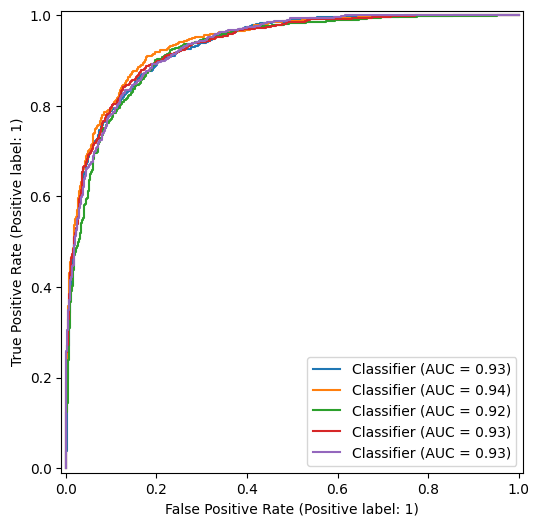

In [250]:

def cross_val_roc(df, n_splits=5):
    # Wydzielenie danych wejściowych i wyjściowych z df
    X = df[["x","y"]].values
    y = df["klasa"].values
    fig, ax = plt.subplots(1, 1, figsize=(6,6))
    # Inicjalizacja StratifiedKFold i pętla po podziałach
    kf=StratifiedKFold(n_splits=n_splits)
    kf.get_n_splits()
    for i, (train_index, test_index) in enumerate(kf.split(X, y)):
      y_prob=train_model(df.iloc[test_index][["x","y"]],df.iloc[train_index][["x","y"]],df.iloc[train_index]["klasa"])
      RocCurveDisplay.from_predictions(df.iloc[test_index]["klasa"],y_prob[:,1],ax=ax)

cross_val_roc(df)

# Przypadek klas niezrównoważonych.

Do tej pory liczebność obu klas w analizowanych danych była równa. Teraz to zmienimy.

**Proszę:**

* korzystając z początkowych zbiorów `class_0_data` oraz `class_1_data` stworzyć zbiór w którym klasy nie będą równoliczne. Niech klasa "1" będzie 100 razy bardziej liczba niż klasa "0".

**Wskazówka**:

stwórz nowy obiekt DataFrame z danych dla klas "0" i "1", ale dobierz próbkowanie danych dla poszczególnych klas, tak by w sumarycznym zbiorze klasa "1" była 100 razy bardziej liczba niż klasa "0".

In [256]:
class_0_data_n=generate_class_data(nPoints,means_class_0,covariance_class_0,0)
class_1_data_n=generate_class_data(nPoints*100,means_class_1,covariance_class_1,1)
df_class_0_n=pd.DataFrame(class_0_data_n)
df_class_1_n=pd.DataFrame(class_1_data_n)
df_n = pd.concat([df_class_0_n, df_class_1_n], ignore_index=True)
#Wymieszanie obiektu DataFrame dla obu klas łącznie
df_n = df_n.sample(frac=1, ignore_index=True)
df_n.rename(columns={0:"x",1:"y",2:"klasa"},inplace=True)

**Proszę:**

Korzystając z metod klasy DataFrame (`value_counts()`), sprawdź czy proporcje są zgodne z założeniami.


In [260]:
print(df_class_0_n.value_counts(),"\n\n",df_class_1_n.value_counts())


0          1         2  
 7.769447  2.755425  0.0    1
-5.052974  8.433198  0.0    1
-4.869256  6.995475  0.0    1
-4.632272  2.873789  0.0    1
-4.610893  5.415571  0.0    1
                           ..
-4.245780  6.618258  0.0    1
-4.312751  6.200257  0.0    1
-4.353958  5.620244  0.0    1
-4.354010  4.893538  0.0    1
-4.417738  1.883762  0.0    1
Name: count, Length: 5000, dtype: int64 

 0           1         2  
 10.983167  7.130710  1.0    1
 10.940221  5.370129  1.0    1
 10.938297  7.102422  1.0    1
 10.881233  7.178013  1.0    1
 10.805670  7.080801  1.0    1
                            ..
-3.247804   4.049060  1.0    1
-3.308867   8.643637  1.0    1
-3.590825   6.240713  1.0    1
-3.761164   6.974580  1.0    1
-3.865075   6.405235  1.0    1
Name: count, Length: 500000, dtype: int64


**Proszę:**

* korzystając z funkcji ```cross_val_metrics(df, n_splits=5)``` oraz ```cross_val_roc(df, n_splits=5)``` wypisz na ekran wartości miar, oraz narysuj krzywe ROC dla danych niezrównoważonych.
* następnie stwórz 'odwrotne' niezbalansowanie klas - niech klasa "0" będzie 100 razy bardziej liczba niż klasa "1" i powtórz punkt wyrzej.
* porównaj metryki dla obu przypadków. Oceń wiarygodność tych metryk dla klas niezbalansowanych.

Przewaga klasy 1:
PPV: 0.992 ± 0.000
TPR: 0.999 ± 0.000
ACC: 0.991 ± 0.000
F1: 0.996 ± 0.000
MCC: 0.357 ± 0.017

Przewaga klasy 0:
PPV: 0.659 ± 0.032
TPR: 0.115 ± 0.010
ACC: 0.991 ± 0.000
F1: 0.196 ± 0.016
MCC: 0.273 ± 0.018


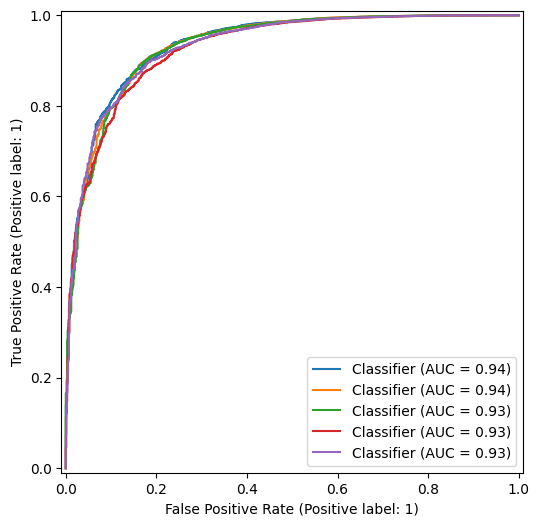

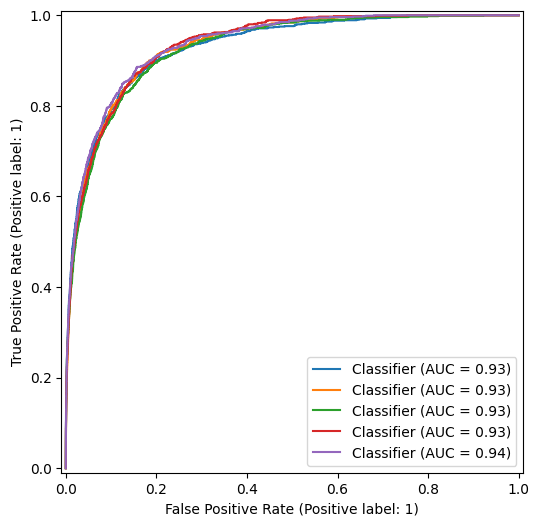

In [265]:
print("Przewaga klasy 1:")
cross_val_metrics(df_n)
cross_val_roc(df_n)

class_0_data_m=generate_class_data(nPoints*100,means_class_0,covariance_class_0,0)
class_1_data_m=generate_class_data(nPoints,means_class_1,covariance_class_1,1)
df_class_0_m=pd.DataFrame(class_0_data_m)
df_class_1_m=pd.DataFrame(class_1_data_m)
df_m = pd.concat([df_class_0_m, df_class_1_m], ignore_index=True)
df_m = df_m.sample(frac=1, ignore_index=True)
df_m.rename(columns={0:"x",1:"y",2:"klasa"},inplace=True)

print("\nPrzewaga klasy 0:")
cross_val_metrics(df_m)
cross_val_roc(df_m)

pass

**Komentarz**

Różnica między F1-score a MCC (Matthews Correlation Coefficient) przy niezbalansowanych klasach jest kluczowa dla rzetelnej oceny modelu. Choć obie metryki są używane jako alternatywa dla zwodniczego Accuracy, podchodzą do problemu w zupełnie inny sposób.

Oto szczegółowe porównanie:

1. Matematyczna symetria i uwzględnianie True Negatives (TN)
Najważniejsza różnica tkwi w tym, które ćwiartki macierzy pomyłek są brane pod uwagę:

F1-score skupia się wyłącznie na klasie pozytywnej (1): $$F_1 = \frac{2TP}{2TP + FP + FN}$$ Jak widzisz, we wzorze zupełnie nie występuje TN (True Negatives – poprawne wskazania klasy większościowej/negatywnej). F1 ocenia jedynie, jak dobrze model radzi sobie z klasą pozytywną.

MCC jest miarą w pełni symetryczną i uwzględnia wszystkie cztery ćwiartki macierzy pomyłek (TP, TN, FP, FN): $$\text{MCC} = \frac{ TP \cdot TN - FP \cdot FN } {\sqrt{ (TP + FP) ( TP + FN ) ( TN + FP ) ( TN + FN ) } }$$ MCC traktuje klasę pozytywną i negatywną z taką samą wagą. Jeśli zamienisz etykiety $0 \leftrightarrow 1$, wartość MCC pozostanie dokładnie taka sama (co widziałeś w wynikach swojej komórki: dla obu przypadków MCC wyniosło $0.253$). F1-score natomiast zmienił się dramatycznie ($0.995 \rightarrow 0.215$).

2. Podatność na "oszukiwanie" przez model (Leniwa klasyfikacja)


Wyobraźmy sobie skrajnie niezbalansowany zbiór danych: 990 próbek klasy 1 i 10 próbek klasy 0. Nasz model jest prymitywny i zawsze przewiduje klasę 1 (ignoruje cechy).

Jak zareaguje F1-score?

Model poprawnie oznacza 990 jedynek ($TP = 990$).
Błędnie oznacza 10 zer jako jedynki ($FP = 10$).
Nie ma żadnych $FN$ ($FN = 0$).
$$F_1 = \frac{2 \cdot 990}{2 \cdot 990 + 10 + 0} = \frac{1980}{1990} \approx \mathbf{0.995}$$ Model, który kompletnie niczego się nie nauczył i ignoruje jedną klasę, otrzymuje niemal idealny wynik F1!

Jak zareaguje MCC?

Ponieważ model nigdy nie przewiduje klasy 0, mamy $TN = 0$ oraz $FN = 0$.
Licznik wzoru MCC to: $TP \cdot TN - FP \cdot FN = 990 \cdot 0 - 10 \cdot 0 = 0$.
$$\text{MCC} = \mathbf{0.0}$$ MCC wynosi $0$, co idealnie odzwierciedla fakt, że model działa na poziomie losowego zgadywania (lub gorzej).

3. Interpretacja skali

F1-score przyjmuje wartości od 0 do 1. Brak punku odniesienia dla losowego zgadywania (wartość dla losowego klasyfikatora zależna jest od proporcji klas w zbiorze, co utrudnia interpretację przy braku balansu).

MCC działa jak standardowy współczynnik korelacji Pearsona w zakresie od -1 do +1:
+1.0 – perfekcyjna klasyfikacja,
0.0 – klasyfikacja losowa / bezużyteczna,
-1.0 – całkowita odwrotność (model zawsze się myli).

Podsumowanie:
Jeśli analizujesz zbiory z silnym niezbalansowaniem klas:

F1-score jest przydatny, jeśli z góry wiesz, że interesuje Cię wyłącznie skuteczność wykrywania rzadkiej klasy (np. wyszukiwanie chorych na rzadką chorobę).

MCC jest znacznie bezpieczniejszą i bardziej obiektywną miarą, jeśli chcesz ocenić ogólną jakość klasyfikatora dwuklasowego, ponieważ ukarze model za ignorowanie którejkolwiek z klas (zarówno mniejszościowej, jak i większościowej).


# Stratyfikacja

W przypadku niezbalansowania klas, zwłaszcza dla niezbyt licznych zbiorów, bardzo ważne jest to, aby podział danych na zbiór treningowy i testowy zachował proporcje klas.

Jeśli tego nie dopilnujemy, może się zdarzyć, że zbiór testowy (lub treningowy) nie będzie zawierał żadnych przykładów mniejszościowej klasy, co prowadzi do błędnej oceny jakości modelu.

Funkcje takie jak train_test_split (z parametrem stratify) czy metody walidacji krzyżowej (cross_val_score) dbają o to automatycznie. Warto jednak zobaczyć, jak wygląda różnica między zwykłym losowym wyborem danych a stratyfikacją.

In [269]:
df_non_equal = pd.concat([df_class_1.sample(frac=0.2), df_class_0.sample(frac=0.01)], ignore_index=True)

print("\nProporcje klas w całym zbiorze:")
print(df_non_equal.label.value_counts(normalize=True))

# --- Podział bez stratyfikacji (losowe 20%) ---
df_test_random = df_non_equal.sample(frac=0.2, random_state=445672)
df_train_random = df_non_equal.drop(df_test_random.index)

print("\nProporcje klas w zbiorze treningowym (losowy podział):")
print(df_train_random["klasa"].value_counts(normalize=True))
print("\nProporcje klas w zbiorze testowym (losowy podział):")
print(df_test_random["klasa"].value_counts(normalize=True))

# --- Podział ze stratyfikacją ---
df_train, df_test = train_test_split(
    df_non_equal,
    test_size=0.2, random_state=42, stratify=df_non_equal["klasa"]
)

print("\nProporcje klas w zbiorze treningowym (stratyfikacja):")
print(df_train["klasa"].value_counts(normalize=True))
print("\nProporcje klas w zbiorze testowym (stratyfikacja):")
print(df_test["klasa"].value_counts(normalize=True))


Proporcje klas w całym zbiorze:

Proporcje klas w zbiorze treningowym (losowy podział):


KeyError: 'klasa'

# Zadanie domowe

Proszę rozważyć dane w których rozkłady klas wyraźnie się różnią, oraz dla takich które się pokrywają:

* klasy nie rozróżnialne: rozkłady (x,y) dla klas "0" i "1" są takie same:
   
   średnie i wariancje zmiennych $x$ i $y$ dla obu klas są identyczne
  
  
* klasa łatwo separowalne: rozkłady (x,y) dla klas "0" i "1" są bardzo różne:
   
  średnie zmiennych $x$ i $y$ dla obu klas różnią się o wartość 2, wariancje są takie same i wynoszą 1

W każdym przypadku proszę rozważyć niezbalansowanie klas na dwa sposoby:
* niech klasa "1" będzie 100 razy bardziej liczna niż klasa "0"
* niech klasa "0" będzie 100 razy bardziej liczna niż klasa "1"

**Proszę:**  

* przeprowadzić analizę modelu: wypisać wartości metryk (print_k_cv_scores).
* skomentować wiarygodność wskazań metryk we wszystkich wariantach w komórce **Wnioski**

***
Przypadek klas nie rozróżnialnych.

In [ ]:
nPoints = 10000
...
##

***
Przypadek gdy klasy są łatwo odróżnialne:

In [ ]:
nPoints = 10000
...
##

# Wnioski:

1) Jak się zachowuje model w sytuacji dużej różnicy częstości występowania dwóch klas?

...

2) Jak zachowują się różne metryki w sytuacji dużej różnicy częstości występowania dwóch klas?

...

3) Jak można przeciwdziałać efektowi częstości występowania?

...

4) Czy efekt częstości występowania ma taki sam czy różny wpływ na miary jakości w przypadku, gdy klasy pochodzą z rozkładów, które się znacząco pokrywają lub są mocno rozseparowane?

...
##